# ĐỒ ÁN OLIST E-COMMERCE ANALYTICS — PostgreSQL/Supabase + Google Colab

**Mục tiêu:** chạy 14 BUSINESS QUESTIONS bằng PostgreSQL; phân tích trong Colab; huấn luyện (1) mô hình phân loại khách hàng có mua lại, (2) dự báo doanh thu theo tháng, (3) phân nhóm khách hàng bằng RFM + K-Means.

**Lưu ý quan trọng:** Notebook chưa kết nối và chưa chạy trên cơ sở dữ liệu Supabase của bạn. Có thêm bước upload CSV và tùy chọn nạp CSV lên Supabase; mặc định chức năng ghi dữ liệu đang tắt để tránh ghi đè. Mọi bảng/kết quả chỉ được xác nhận sau khi bạn chạy các ô. Dataset Olist chuẩn thường có 9 bảng với tên `olist_*_dataset`; nếu tên/cột của bạn khác, chạy ô kiểm tra schema và sửa theo kết quả.

**Cách dùng:** chạy từng ô từ trên xuống. Không dán mật khẩu database trực tiếp vào notebook đã chia sẻ.

## 0. Cài thư viện
Chạy một lần mỗi khi khởi động runtime Colab.

In [1]:
%pip -q install "sqlalchemy>=2.0" "psycopg[binary]" pandas numpy matplotlib seaborn scikit-learn plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.5/215.5 kB 8.8 MB/s eta 0:00:00


## 1. Kết nối an toàn tới Supabase PostgreSQL
Trong Supabase mở **Project Settings → Database → Connection string**. Lấy host, database, user, password và port. Với kết nối trực tiếp dùng port thường là `5432`; nếu mạng Colab không kết nối được, thử **Session pooler** theo thông tin Supabase cung cấp (không tự đoán host/user/port).

Không đưa password vào cell hoặc commit lên GitHub. Cell dưới đây hỏi mật khẩu riêng khi chạy.

In [ ]:
import os, getpass, urllib.parse
import pandas as pd
import numpy as np
from sqlalchemy import create_engine, text

DB_HOST = input("Supabase host (chỉ hostname, không có https://): ").strip()
DB_PORT = input("Port [5432]: ").strip() or "5432"
DB_NAME = input("Database [postgres]: ").strip() or "postgres"
DB_USER = input("Database user: ").strip()
DB_PASSWORD = getpass.getpass("Database password (không hiển thị): ")

# URL encode thông tin đăng nhập để tránh lỗi với ký tự đặc biệt.
url = (f"postgresql+psycopg://{urllib.parse.quote_plus(DB_USER)}:"
       f"{urllib.parse.quote_plus(DB_PASSWORD)}@{DB_HOST}:{DB_PORT}/"
       f"{urllib.parse.quote_plus(DB_NAME)}?sslmode=require")
engine = create_engine(url, pool_pre_ping=True, connect_args={"connect_timeout": 15})
with engine.connect() as conn:
    print(conn.execute(text("SELECT current_database(), current_user, version() ")).fetchone())
print("Kết nối thành công. Nếu có lỗi, chưa chạy các phần truy vấn/ML.")

## 1A. Tải dữ liệu Olist CSV vào Google Colab

Cell này cho phép tải lên **một file ZIP chứa các CSV** hoặc chọn nhiều file CSV trực tiếp. Có thể dùng bộ CSV Olist chuẩn gồm customers, geolocation, order items, payments, reviews, orders, products, sellers và category translation. Nếu ZIP có thư mục con, notebook sẽ tìm CSV bên trong.

> File `Olist data.sql` bạn gửi là script truy vấn/làm sạch theo cú pháp SQL Server; nó không chứa bản ghi dữ liệu CSV. Bạn cần tải bộ CSV Olist riêng (hoặc dùng các CSV đang có). Không cần đưa file `.sql` vào ô upload này.


In [3]:
from pathlib import Path
from google.colab import files
import zipfile, shutil, os

DATA_DIR = Path('/content/olist_data')
DATA_DIR.mkdir(parents=True, exist_ok=True)

print('Chọn file ZIP chứa CSV Olist hoặc chọn nhiều file .csv. Có thể bấm Cancel nếu đã có dữ liệu trong /content/olist_data.')
uploaded = files.upload()
for uploaded_name in uploaded:
    src = Path('/content') / uploaded_name
    if uploaded_name.lower().endswith('.zip'):
        with zipfile.ZipFile(src) as zf:
            zf.extractall(DATA_DIR)
        print(f'Đã giải nén: {uploaded_name}')
    elif uploaded_name.lower().endswith('.csv'):
        shutil.copy2(src, DATA_DIR / uploaded_name)
        print(f'Đã nhận CSV: {uploaded_name}')
    else:
        print(f'Bỏ qua file không phải CSV/ZIP: {uploaded_name}')

found_csv = sorted(DATA_DIR.rglob('*.csv'))
print(f'\nTìm thấy {len(found_csv)} file CSV trong {DATA_DIR}')
for p in found_csv:
    print(f'- {p.relative_to(DATA_DIR)} ({p.stat().st_size/1024/1024:.1f} MB)')


Chọn file ZIP chứa CSV Olist hoặc chọn nhiều file .csv. Có thể bấm Cancel nếu đã có dữ liệu trong /content/olist_data.


Saving archive.zip to archive.zip
Đã giải nén: archive.zip

Tìm thấy 9 file CSV trong /content/olist_data
- olist_customers_dataset.csv (8.6 MB)
- olist_geolocation_dataset.csv (58.4 MB)
- olist_order_items_dataset.csv (14.7 MB)
- olist_order_payments_dataset.csv (5.5 MB)
- olist_order_reviews_dataset.csv (13.8 MB)
- olist_orders_dataset.csv (16.8 MB)
- olist_products_dataset.csv (2.3 MB)
- olist_sellers_dataset.csv (0.2 MB)
- product_category_name_translation.csv (0.0 MB)


## 1B. Đọc và kiểm tra các CSV

Notebook dùng tên bảng gốc theo `Olist data.sql`. Các cột ngày được chuyển sang datetime để PostgreSQL/Colab có thể phân tích thời gian. Geolocation có thể rất lớn, vì vậy mặc định chỉ đọc/nạp khi bạn chủ động bật.


In [4]:
import pandas as pd
from pathlib import Path

# Ánh xạ tên CSV gốc -> tên bảng PostgreSQL mà Olist data.sql sử dụng.
CSV_TO_TABLE = {
    'olist_customers_dataset.csv': 'olist_customers_dataset',
    'olist_geolocation_dataset.csv': 'olist_geolocation_dataset',
    'olist_order_items_dataset.csv': 'olist_order_items_dataset',
    'olist_order_payments_dataset.csv': 'olist_order_payments_dataset',
    'olist_order_reviews_dataset.csv': 'olist_order_reviews_dataset',
    'olist_orders_dataset.csv': 'olist_orders_dataset',
    'olist_products_dataset.csv': 'olist_products_dataset',
    'olist_sellers_dataset.csv': 'olist_sellers_dataset',
    'product_category_name_translation.csv': 'product_category_name_translation',
}

# Đọc CSV tìm thấy ở mọi thư mục con. Nếu có tên file trùng, dùng file đầu tiên theo đường dẫn.
csv_paths = {}
for p in sorted(DATA_DIR.rglob('*.csv')):
    csv_paths.setdefault(p.name.lower(), p)

missing_core = [f for f in [
    'olist_customers_dataset.csv','olist_order_items_dataset.csv',
    'olist_order_payments_dataset.csv','olist_order_reviews_dataset.csv',
    'olist_orders_dataset.csv','olist_products_dataset.csv','olist_sellers_dataset.csv'
] if f not in csv_paths]
if missing_core:
    raise FileNotFoundError('Thiếu CSV bắt buộc: ' + ', '.join(missing_core) +
        '. Hãy upload ZIP/bộ CSV Olist đúng tên file rồi chạy lại cell này.')

dfs_csv = {}
for filename, table_name in CSV_TO_TABLE.items():
    path = csv_paths.get(filename)
    if path is None:
        print(f'Không có {filename}; bỏ qua bảng {table_name}.')
        continue
    # Olist dùng dấu phẩy và UTF-8; low_memory=False tránh suy luận kiểu không nhất quán.
    df = pd.read_csv(path, low_memory=False, encoding='utf-8')
    # Chuẩn hóa tên cột dạng khoảng trắng, không đổi tên cột gốc Olist.
    df.columns = [str(c).strip() for c in df.columns]
    date_cols = {
        'olist_orders_dataset.csv': ['order_purchase_timestamp','order_approved_at','order_delivered_carrier_date','order_delivered_customer_date','order_estimated_delivery_date'],
        'olist_order_items_dataset.csv': ['shipping_limit_date'],
        'olist_order_reviews_dataset.csv': ['review_creation_date','review_answer_timestamp'],
    }.get(filename, [])
    for col in date_cols:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors='coerce')
    dfs_csv[table_name] = df
    print(f'{table_name}: {len(df):,} dòng × {len(df.columns)} cột')
    display(df.head(2))

print('Đã đọc', len(dfs_csv), 'bảng CSV. Dữ liệu hiện nằm trong bộ nhớ Colab, chưa ghi lên Supabase.')


olist_customers_dataset: 99,441 dòng × 5 cột


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP


olist_geolocation_dataset: 1,000,163 dòng × 5 cột


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP


olist_order_items_dataset: 112,650 dòng × 7 cột


...

olist_sellers_dataset: 3,095 dòng × 4 cột


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP


product_category_name_translation: 71 dòng × 2 cột


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories


Đã đọc 9 bảng CSV. Dữ liệu hiện nằm trong bộ nhớ Colab, chưa ghi lên Supabase.


## 1C. (Tùy chọn) Nạp CSV từ Colab lên Supabase

**Mặc định tắt để tránh ghi đè dữ liệu.** Chỉ bật nếu bạn muốn tạo/nạp bảng trong schema `public` của Supabase. Cell sẽ dừng nếu phát hiện bảng trùng tên; để thay thế bảng hiện có, bạn phải đổi `REPLACE_EXISTING_TABLES = True` sau khi đã sao lưu. Thay thế bảng có thể xóa khóa/index hiện có và là thao tác phá hủy dữ liệu.

Geolocation có nhiều dòng và không cần cho hầu hết 14 câu hỏi/ba mô hình ML, nên mặc định không nạp bảng này.


In [5]:
from sqlalchemy import inspect

IMPORT_TO_SUPABASE = False        # Đổi thành True nếu thực sự muốn nạp lên Supabase
REPLACE_EXISTING_TABLES = False    # Chỉ True khi chấp nhận xóa/thay thế các bảng cùng tên
INCLUDE_GEOLOCATION = False      # Bật nếu cần phân tích bảng geolocation; có thể nạp rất lâu

if IMPORT_TO_SUPABASE:
    tables_to_load = [
        'product_category_name_translation',
        'olist_customers_dataset', 'olist_sellers_dataset', 'olist_products_dataset',
        'olist_orders_dataset', 'olist_order_items_dataset',
        'olist_order_payments_dataset', 'olist_order_reviews_dataset'
    ]
    if INCLUDE_GEOLOCATION and 'olist_geolocation_dataset' in dfs_csv:
        tables_to_load.append('olist_geolocation_dataset')
    tables_to_load = [t for t in tables_to_load if t in dfs_csv]

    existing = set(inspect(engine).get_table_names(schema='public'))
    collisions = sorted(existing.intersection(tables_to_load))
    if collisions and not REPLACE_EXISTING_TABLES:
        raise RuntimeError(
            'Các bảng sau đã tồn tại trong public: ' + ', '.join(collisions) +
            '. Để bảo toàn dữ liệu, notebook đã dừng. Hãy sao lưu trước; nếu muốn thay thế, đặt REPLACE_EXISTING_TABLES=True và chạy lại cell.'
        )

    # Đọc theo thứ tự tiện dụng; chunk nhỏ để giảm bộ nhớ và kích thước batch.
    for table in tables_to_load:
        df = dfs_csv[table]
        if REPLACE_EXISTING_TABLES and table in existing:
            mode = 'replace'
        else:
            mode = 'fail'
        print(f'Đang nạp {table}: {len(df):,} dòng ...')
        df.to_sql(table, engine, schema='public', if_exists=mode, index=False,
                  chunksize=1000, method='multi')
        print(f'Đã nạp {table}.')
    print('Hoàn tất. Hãy chạy lại cell kiểm tra bảng/cột ở phần tiếp theo.')
else:
    print('Chưa nạp lên Supabase. CSV đã có trong dfs_csv để kiểm tra/ phân tích trong Colab.')


Chưa nạp lên Supabase. CSV đã có trong dfs_csv để kiểm tra/ phân tích trong Colab.


## 2. Kiểm tra bảng và cột trước khi chạy phân tích
Nếu một bảng không tồn tại hoặc tên cột khác, hãy sửa tên trong SQL trước khi tiếp tục. Dataset chuẩn thường dùng các bảng `olist_orders_dataset`, `olist_order_items_dataset`, `olist_order_payments_dataset`, `olist_order_reviews_dataset`, `olist_products_dataset`, `olist_customers_dataset`, `olist_sellers_dataset`, `olist_geolocation_dataset`, `product_category_name_translation` (bảng dịch có thể tên khác).

In [6]:
schema_df = pd.read_sql_query(text("""
SELECT table_schema, table_name
FROM information_schema.tables
WHERE table_schema NOT IN ('pg_catalog','information_schema')
  AND table_type = 'BASE TABLE'
ORDER BY table_schema, table_name
"""), engine)
display(schema_df)

# Liệt kê cột của các bảng public để đối chiếu với SQL.
columns_df = pd.read_sql_query(text("""
SELECT table_name, ordinal_position, column_name, data_type
FROM information_schema.columns
WHERE table_schema = 'public'
ORDER BY table_name, ordinal_position
"""), engine)
display(columns_df)

,table_schema,table_name
0,auth,audit_log_entries
1,auth,custom_oauth_providers
2,auth,flow_state
3,auth,identities
4,auth,instances
5,auth,mfa_amr_claims
6,auth,mfa_challenges
7,auth,mfa_factors
8,auth,mfa_recovery_code_sets
9,auth,mfa_recovery_codes


,table_name,ordinal_position,column_name,data_type
0,olist_customers_dataset,1,customer_id,text
1,olist_customers_dataset,2,customer_unique_id,text
2,olist_customers_dataset,3,customer_zip_code_prefix,bigint
3,olist_customers_dataset,4,customer_city,text
4,olist_customers_dataset,5,customer_state,text
5,olist_geolocation_dataset,1,geolocation_zip_code_prefix,bigint
6,olist_geolocation_dataset,2,geolocation_lat,double precision
7,olist_geolocation_dataset,3,geolocation_lng,double precision
8,olist_geolocation_dataset,4,geolocation_city,text
9,olist_geolocation_dataset,5,geolocation_state,text


## 3. Phân tích 14 câu hỏi nghiệp vụ (SQL chạy riêng từng phần)

Mỗi câu hỏi được tách thành một mục Markdown và một ô code riêng. Chạy lần lượt từng ô để xem bảng kết quả trong Colab. Các truy vấn dùng PostgreSQL qua kết nối `engine` đã tạo ở phần 1; cần nạp đủ các bảng CSV hoặc kết nối tới Supabase trước khi chạy.

### Q1 — Doanh thu theo tháng

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 1. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [7]:
# Câu hỏi 1: Q1 — Doanh thu theo tháng
query_sql = """SELECT date_trunc('month', o.order_purchase_timestamp)::date AS month,
       round(sum(p.payment_value)::numeric, 2) AS revenue_brl
FROM olist_orders_dataset o
JOIN (SELECT order_id, sum(payment_value) payment_value
      FROM olist_order_payments_dataset GROUP BY order_id) p USING(order_id)
WHERE o.order_status NOT IN ('canceled','unavailable')
  AND o.order_purchase_timestamp IS NOT NULL
GROUP BY 1 ORDER BY 1"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,month,revenue_brl
0,2016-09-01,136.23
1,2016-10-01,51657.53
2,2016-12-01,19.62
3,2017-01-01,137006.76
4,2017-02-01,283621.94
5,2017-03-01,425656.40
6,2017-04-01,405988.38
7,2017-05-01,582926.16
8,2017-06-01,499827.47
9,2017-07-01,578858.58


Số dòng kết quả: 24


### Q2 — Số đơn theo tháng

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 2. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [8]:
# Câu hỏi 2: Q2 — Số đơn theo tháng
query_sql = """SELECT date_trunc('month', order_purchase_timestamp)::date AS month,
       count(*) AS orders
FROM olist_orders_dataset
WHERE order_purchase_timestamp IS NOT NULL
GROUP BY 1 ORDER BY 1"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,month,orders
0,2016-09-01,4
1,2016-10-01,324
2,2016-12-01,1
3,2017-01-01,800
4,2017-02-01,1780
5,2017-03-01,2682
6,2017-04-01,2404
7,2017-05-01,3700
8,2017-06-01,3245
9,2017-07-01,4026


Số dòng kết quả: 25


### Q3 — Danh mục bán chạy

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 3. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [9]:
# Câu hỏi 3: Q3 — Danh mục bán chạy
query_sql = """SELECT coalesce(p.product_category_name,'unknown') category,
       count(*) item_lines, count(distinct oi.order_id) orders,
       round(sum(oi.price)::numeric,2) merchandise_revenue_brl
FROM olist_order_items_dataset oi
JOIN olist_orders_dataset o USING(order_id)
JOIN olist_products_dataset p USING(product_id)
WHERE o.order_status NOT IN ('canceled','unavailable')
GROUP BY 1 ORDER BY item_lines DESC LIMIT 30"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,category,item_lines,orders,merchandise_revenue_brl
0,cama_mesa_banho,11097,9399,1035964.06
1,beleza_saude,9634,8800,1255695.13
2,esporte_lazer,8590,7673,979740.92
3,moveis_decoracao,8298,6425,727465.05
4,informatica_acessorios,7781,6654,904322.02
5,utilidades_domesticas,6915,5847,626825.80
6,relogios_presentes,5970,5604,1198185.21
7,telefonia,4527,4183,322342.64
8,ferramentas_jardim,4328,3505,481009.94
9,automotivo,4204,3872,586585.73


Số dòng kết quả: 30


### Q4 — AOV theo phương thức thanh toán

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 4. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [10]:
# Câu hỏi 4: Q4 — AOV theo phương thức thanh toán
query_sql = """WITH op AS (SELECT order_id, payment_type, sum(payment_value) amount
            FROM olist_order_payments_dataset GROUP BY order_id,payment_type),
valid AS (SELECT order_id FROM olist_orders_dataset
          WHERE order_status NOT IN ('canceled','unavailable'))
SELECT op.payment_type, count(distinct op.order_id) orders,
       round(avg(op.amount)::numeric,2) avg_payment_per_order_brl,
       round(sum(op.amount)::numeric,2) payment_total_brl
FROM op JOIN valid USING(order_id)
GROUP BY op.payment_type ORDER BY orders DESC"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,payment_type,orders,avg_payment_per_order_brl,payment_total_brl
0,credit_card,75618,163.32,12350042.56
1,boleto,19539,144.67,2826802.30
2,voucher,3745,93.42,349874.40
3,debit_card,1515,140.21,212417.75


Số dòng kết quả: 4


### Q5 — Seller hoạt động theo quý

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 5. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [11]:
# Câu hỏi 5: Q5 — Seller hoạt động theo quý
query_sql = """SELECT date_trunc('quarter',o.order_purchase_timestamp)::date quarter,
       count(distinct oi.seller_id) active_sellers
FROM olist_orders_dataset o JOIN olist_order_items_dataset oi USING(order_id)
WHERE o.order_status NOT IN ('canceled','unavailable')
  AND o.order_purchase_timestamp IS NOT NULL
GROUP BY 1 ORDER BY 1"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,quarter,active_sellers
0,2016-07-01,2
1,2016-10-01,134
2,2017-01-01,651
3,2017-04-01,806
4,2017-07-01,998
5,2017-10-01,1258
6,2018-01-01,1370
7,2018-04-01,1662
8,2018-07-01,1608


Số dòng kết quả: 9


### Q6 — Phân phối review score

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 6. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [12]:
# Câu hỏi 6: Q6 — Phân phối review score
query_sql = """SELECT review_score, count(*) review_rows, count(distinct order_id) orders
FROM olist_order_reviews_dataset GROUP BY review_score ORDER BY review_score"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,review_score,review_rows,orders
0,1,11424,11393
1,2,3151,3148
2,3,8179,8160
3,4,19142,19098
4,5,57328,57076


Số dòng kết quả: 5


### Q7 — Khách mua lại và tỷ trọng doanh thu

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 7. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [15]:
# Câu hỏi 7: Q7 — Khách mua lại và tỷ trọng doanh thu
query_sql = """WITH rev AS (SELECT order_id,sum(payment_value) amount FROM olist_order_payments_dataset GROUP BY order_id),
co AS (SELECT c.customer_unique_id,o.order_id,coalesce(rev.amount,0) amount
       FROM olist_customers_dataset c JOIN olist_orders_dataset o USING(customer_id)
       LEFT JOIN rev USING(order_id)
       WHERE o.order_status NOT IN ('canceled','unavailable')),
cs AS (SELECT customer_unique_id,count(distinct order_id) n_orders,sum(amount) spend
       FROM co GROUP BY customer_unique_id)
SELECT count(*) customers,
       count(*) FILTER(WHERE n_orders>1) repeat_customers,
       round((100.0*count(*) FILTER(WHERE n_orders>1)/nullif(count(*),0))::numeric,2) repeat_rate_pct,
       round((100.0*sum(spend) FILTER(WHERE n_orders>1)/nullif(sum(spend),0))::numeric,2) repeat_revenue_share_pct
FROM cs"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,customers,repeat_customers,repeat_rate_pct,repeat_revenue_share_pct
0,94990,2888,3.04,5.66


Số dòng kết quả: 1


### Q8 — Điểm review trung bình

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 8. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [16]:
# Câu hỏi 8: Q8 — Điểm review trung bình
query_sql = """SELECT round(avg(review_score)::numeric,2) avg_review_score,
       count(*) review_rows, count(*) FILTER(WHERE review_score IS NULL) missing_scores
FROM olist_order_reviews_dataset"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,avg_review_score,review_rows,missing_scores
0,4.09,99224,0


Số dòng kết quả: 1


### Q9 — Tỷ lệ hủy đơn

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 9. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [17]:
# Câu hỏi 9: Q9 — Tỷ lệ hủy đơn
query_sql = """SELECT count(*) all_orders,
       count(*) FILTER(WHERE order_status='canceled') canceled_orders,
       round(100.0*count(*) FILTER(WHERE order_status='canceled')/nullif(count(*),0),2) cancellation_rate_pct
FROM olist_orders_dataset"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,all_orders,canceled_orders,cancellation_rate_pct
0,99441,625,0.63


Số dòng kết quả: 1


### Q10 — Top sản phẩm theo doanh thu hàng hóa

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 10. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [18]:
# Câu hỏi 10: Q10 — Top sản phẩm theo doanh thu hàng hóa
query_sql = """SELECT oi.product_id, coalesce(p.product_category_name,'unknown') category,
       count(*) item_lines, count(distinct oi.order_id) orders,
       round(sum(oi.price)::numeric,2) merchandise_revenue_brl
FROM olist_order_items_dataset oi JOIN olist_orders_dataset o USING(order_id)
JOIN olist_products_dataset p USING(product_id)
WHERE o.order_status NOT IN ('canceled','unavailable')
GROUP BY oi.product_id,2 ORDER BY item_lines DESC LIMIT 20"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,product_id,category,item_lines,orders,merchandise_revenue_brl
0,aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,527,431,37608.90
1,99a4788cb24856965c36a24e339b6058,cama_mesa_banho,487,466,42938.66
2,422879e10f46682990de24d770e7f83d,ferramentas_jardim,484,352,26577.22
3,389d119b48cf3043d311335e499d9c6b,ferramentas_jardim,391,310,21390.69
4,368c6c730842d78016ad823897a372db,ferramentas_jardim,388,291,21056.80
5,53759a2ecddad2bb87a079a1f1519f73,ferramentas_jardim,373,287,20387.20
6,d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,341,321,46916.51
7,53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,323,306,37683.42
8,154e7e31ebfa092203795c972e5804a6,beleza_saude,281,269,6325.19
9,3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,274,255,41082.60


Số dòng kết quả: 20


### Q11 — Phương thức thanh toán

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 11. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [19]:
# Câu hỏi 11: Q11 — Phương thức thanh toán
query_sql = """SELECT payment_type, count(distinct order_id) orders,
       round(sum(payment_value)::numeric,2) payment_total_brl
FROM olist_order_payments_dataset GROUP BY payment_type ORDER BY orders DESC"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,payment_type,orders,payment_total_brl
0,credit_card,76505,12542084.19
1,boleto,19784,2869361.27
2,voucher,3866,379436.87
3,debit_card,1528,217989.79
4,not_defined,3,0.00


Số dòng kết quả: 5


### Q12 — Review và doanh thu theo điểm

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 12. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [20]:
# Câu hỏi 12: Q12 — Review và doanh thu theo điểm
query_sql = """WITH pay AS (SELECT order_id,sum(payment_value) amount FROM olist_order_payments_dataset GROUP BY order_id)
SELECT r.review_score,count(distinct r.order_id) orders,
       round(avg(pay.amount)::numeric,2) avg_order_payment_brl,
       round(sum(pay.amount)::numeric,2) payment_total_brl
FROM olist_order_reviews_dataset r JOIN pay USING(order_id)
JOIN olist_orders_dataset o USING(order_id)
WHERE o.order_status NOT IN ('canceled','unavailable')
GROUP BY r.review_score ORDER BY r.review_score"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,review_score,orders,avg_order_payment_brl,payment_total_brl
0,1,10509,192.83,2032074.91
1,2,3061,170.78,523259.38
2,3,8077,151.05,1222902.29
3,4,19052,154.67,2953672.45
4,5,56973,156.19,8937670.71


Số dòng kết quả: 5


### Q13 — Doanh thu hàng hóa và tỷ lệ phí vận chuyển (không phải profit margin)

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 13. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [21]:
# Câu hỏi 13: Q13 — Doanh thu hàng hóa và tỷ lệ phí vận chuyển
# (không phải profit margin)

query_sql = """
SELECT
    COALESCE(p.product_category_name, 'unknown') AS category,
    ROUND(SUM(oi.price)::numeric, 2) AS merchandise_revenue_brl,
    ROUND(SUM(oi.freight_value)::numeric, 2) AS freight_brl,
    ROUND(
        (
            100.0 * SUM(oi.freight_value)
            / NULLIF(SUM(oi.price), 0)
        )::numeric,
        2
    ) AS freight_to_item_revenue_pct
FROM olist_order_items_dataset oi
JOIN olist_products_dataset p USING (product_id)
JOIN olist_orders_dataset o USING (order_id)
WHERE o.order_status NOT IN ('canceled', 'unavailable')
GROUP BY 1
ORDER BY merchandise_revenue_brl DESC
"""

try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,category,merchandise_revenue_brl,freight_brl,freight_to_item_revenue_pct
0,beleza_saude,1255695.13,181970.65,14.49
1,relogios_presentes,1198185.21,100107.26,8.35
2,cama_mesa_banho,1035964.06,204422.07,19.73
3,esporte_lazer,979740.92,167503.71,17.10
4,informatica_acessorios,904322.02,146619.56,16.21
...,...,...,...,...
69,flores,1110.04,488.87,44.04
70,casa_conforto_2,760.27,410.31,53.97
71,cds_dvds_musicais,730.00,224.99,30.82
72,fashion_roupa_infanto_juvenil,569.85,95.51,16.76


Số dòng kết quả: 74


### Q14 — Retention theo bang khách hàng

**Mục đích:** dùng kết quả để trả lời câu hỏi nghiệp vụ số 14. Kiểm tra tên bảng/cột nếu schema thực tế khác bộ dữ liệu Olist chuẩn.

In [22]:
# Câu hỏi 14: Q14 — Retention theo bang khách hàng
query_sql = """WITH x AS (SELECT c.customer_unique_id,c.customer_state,count(distinct o.order_id) n_orders
           FROM olist_customers_dataset c JOIN olist_orders_dataset o USING(customer_id)
           WHERE o.order_status NOT IN ('canceled','unavailable')
           GROUP BY c.customer_unique_id,c.customer_state)
SELECT customer_state,count(*) customers,
       count(*) FILTER(WHERE n_orders>1) repeat_customers,
       round(100.0*count(*) FILTER(WHERE n_orders>1)/nullif(count(*),0),2) retention_rate_pct
FROM x GROUP BY customer_state ORDER BY customers DESC"""
try:
    result_df = pd.read_sql_query(text(query_sql), engine)
    display(result_df.head(100))
    print(f"Số dòng kết quả: {len(result_df):,}")
except Exception as e:
    print("Truy vấn chưa chạy được. Kiểm tra kết nối Supabase, tên bảng/cột và kiểu dữ liệu.")
    raise


,customer_state,customers,repeat_customers,retention_rate_pct
0,SP,39749,1241,3.12
1,RJ,12242,410,3.35
2,MG,11134,326,2.93
3,RS,5234,163,3.11
4,PR,4825,140,2.90
5,SC,3502,91,2.60
6,BA,3244,90,2.77
7,DF,2058,60,2.92
8,ES,1950,57,2.92
9,GO,1934,60,3.10


Số dòng kết quả: 27


## 4. Chuẩn bị bộ dữ liệu phân tích cho Machine Learning
Các ô dưới đây truy vấn dữ liệu gốc và tạo bảng trung gian trong bộ nhớ Colab. Chúng không sửa hoặc ghi đè bảng Supabase. Mặc định chỉ tính đơn không ở trạng thái `canceled` hoặc `unavailable` cho doanh thu/đặc trưng mua hàng.

In [48]:
monthly_sql = """
SELECT date_trunc('month', o.order_purchase_timestamp)::date AS month,
       sum(p.payment_value)::float AS revenue
FROM olist_orders_dataset o
JOIN (SELECT order_id, sum(payment_value) payment_value
      FROM olist_order_payments_dataset GROUP BY order_id) p USING(order_id)
WHERE o.order_status NOT IN ('canceled','unavailable')
  AND o.order_purchase_timestamp IS NOT NULL
GROUP BY 1 ORDER BY 1
"""
monthly = pd.read_sql_query(text(monthly_sql), engine, parse_dates=['month'])
monthly = monthly.dropna().sort_values('month').reset_index(drop=True)
print('Số tháng dữ liệu:', len(monthly), '| khoảng:', monthly['month'].min(), '→', monthly['month'].max())
display(monthly.tail())

Số tháng dữ liệu: 24 | khoảng: 2016-09-01 00:00:00 → 2018-09-01 00:00:00


,month,revenue
19,2018-05-01,1145748.63
20,2018-06-01,1020494.29
21,2018-07-01,1039880.16
22,2018-08-01,996896.15
23,2018-09-01,166.46


# 5. Mô hình 1 — Dự đoán khách hàng có mua lại
**Mục tiêu được cố định:** dự đoán liệu khách hàng có phát sinh đơn hợp lệ thứ hai trong vòng 90 ngày kể từ đơn hợp lệ đầu tiên hay không. Chỉ giữ khách hàng có đủ 90 ngày quan sát trong dữ liệu để tránh thiên lệch do khách ở cuối dataset có ít thời gian mua lại hơn.

**Đặc trưng:** trạng thái khách hàng, danh mục phổ biến nhất trong đơn đầu, tổng thanh toán, số lần trả góp, loại phương thức thanh toán, số lượng/giá trị sản phẩm và tháng/năm mua đầu tiên. Không dùng review_score vì đánh giá có thể chỉ xuất hiện sau khi mua hàng. Chia train/validation/test theo thời gian của đơn đầu tiên. Kết quả chỉ phản ánh hành vi trong dataset Olist, không đảm bảo dự đoán hành vi hiện tại ngoài đời.

In [52]:
# Mô hình 1 — Chuẩn bị dữ liệu dự đoán mua lại trong 90 ngày
# Nhãn cố định 90 ngày; đặc trưng chỉ lấy từ đơn đầu tiên, không dùng review sau mua.

customer_feature_sql = """
WITH valid_orders AS MATERIALIZED (
    SELECT
        o.order_id,
        o.customer_id,
        o.order_purchase_timestamp,
        c.customer_unique_id,
        c.customer_state
    FROM olist_orders_dataset o
    JOIN olist_customers_dataset c
      ON c.customer_id = o.customer_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
      AND o.order_purchase_timestamp IS NOT NULL
),
first_order AS MATERIALIZED (
    SELECT DISTINCT ON (customer_unique_id)
        customer_unique_id,
        order_id,
        customer_id,
        order_purchase_timestamp,
        customer_state
    FROM valid_orders
    ORDER BY customer_unique_id, order_purchase_timestamp, order_id
),
eligible_customers AS (
    SELECT f.*
    FROM first_order f
    CROSS JOIN (
        SELECT MAX(order_purchase_timestamp) AS max_date
        FROM valid_orders
    ) d
    WHERE f.order_purchase_timestamp <= d.max_date - INTERVAL '90 days'
),
repeat_flags AS (
    SELECT
        f.customer_unique_id,
        MAX(
            CASE
                WHEN v.order_purchase_timestamp > f.order_purchase_timestamp
                 AND v.order_purchase_timestamp <=
                     f.order_purchase_timestamp + INTERVAL '90 days'
                THEN 1 ELSE 0
            END
        ) AS repeat_label
    FROM eligible_customers f
    LEFT JOIN valid_orders v
      ON v.customer_unique_id = f.customer_unique_id
     AND v.order_purchase_timestamp > f.order_purchase_timestamp
     AND v.order_purchase_timestamp <=
         f.order_purchase_timestamp + INTERVAL '90 days'
    GROUP BY f.customer_unique_id
),
order_value AS (
    SELECT
        p.order_id,
        SUM(p.payment_value)::double precision AS payment_value,
        AVG(p.payment_installments)::double precision AS avg_payment_installments,
        MAX(CASE WHEN p.payment_type = 'credit_card' THEN 1 ELSE 0 END)::int
            AS pay_credit_card,
        MAX(CASE WHEN p.payment_type = 'boleto' THEN 1 ELSE 0 END)::int
            AS pay_boleto,
        MAX(CASE WHEN p.payment_type = 'debit_card' THEN 1 ELSE 0 END)::int
            AS pay_debit_card,
        MAX(CASE WHEN p.payment_type = 'voucher' THEN 1 ELSE 0 END)::int
            AS pay_voucher
    FROM olist_order_payments_dataset p
    JOIN eligible_customers f ON f.order_id = p.order_id
    GROUP BY p.order_id
),
item_features AS (
    SELECT
        i.order_id,
        COUNT(*)::double precision AS item_count,
        SUM(i.price)::double precision AS item_value
    FROM olist_order_items_dataset i
    JOIN eligible_customers f ON f.order_id = i.order_id
    GROUP BY i.order_id
),
item_category_counts AS (
    SELECT
        i.order_id,
        COALESCE(p.product_category_name, 'unknown') AS category,
        COUNT(*) AS category_items
    FROM olist_order_items_dataset i
    JOIN eligible_customers f ON f.order_id = i.order_id
    LEFT JOIN olist_products_dataset p ON p.product_id = i.product_id
    GROUP BY i.order_id, COALESCE(p.product_category_name, 'unknown')
),
first_item_category AS (
    SELECT DISTINCT ON (order_id)
        order_id,
        category AS first_product_category
    FROM item_category_counts
    ORDER BY order_id, category_items DESC, category
)
SELECT
    f.customer_unique_id,
    f.order_id,
    f.order_purchase_timestamp AS first_order_date,
    f.customer_state,
    COALESCE(v.payment_value, 0) AS first_payment_value,
    COALESCE(v.avg_payment_installments, 0) AS first_payment_installments,
    COALESCE(v.pay_credit_card, 0) AS pay_credit_card,
    COALESCE(v.pay_boleto, 0) AS pay_boleto,
    COALESCE(v.pay_debit_card, 0) AS pay_debit_card,
    COALESCE(v.pay_voucher, 0) AS pay_voucher,
    COALESCE(i.item_count, 0) AS first_item_count,
    COALESCE(i.item_value, 0) AS first_item_value,
    COALESCE(cat.first_product_category, 'unknown') AS first_product_category,
    EXTRACT(MONTH FROM f.order_purchase_timestamp)::int AS first_order_month,
    EXTRACT(YEAR FROM f.order_purchase_timestamp)::int AS first_order_year,
    COALESCE(r.repeat_label, 0)::int AS repeat_label
FROM eligible_customers f
LEFT JOIN repeat_flags r USING (customer_unique_id)
LEFT JOIN order_value v USING (order_id)
LEFT JOIN item_features i USING (order_id)
LEFT JOIN first_item_category cat USING (order_id)
"""


customer_ml = pd.read_sql_query(
    text(customer_feature_sql),
    engine,
    parse_dates=["first_order_date"]
)

customer_ml = (
    customer_ml.drop_duplicates("customer_unique_id")
    .sort_values("first_order_date")
    .reset_index(drop=True)
)


print("Số khách đủ 90 ngày quan sát:", f"{len(customer_ml):,}")
print("Định nghĩa nhãn: có đơn hợp lệ tiếp theo trong vòng 90 ngày sau đơn đầu.")
print("Tỷ lệ mua lại 90 ngày:", f"{customer_ml['repeat_label'].mean():.2%}")
display(
    customer_ml["repeat_label"]
    .value_counts()
    .rename(index={0: "Không mua lại trong 90 ngày", 1: "Có mua lại trong 90 ngày"})
    .to_frame("Số khách hàng")
)
display(customer_ml.head())


Số khách đủ 90 ngày quan sát: 77,568
Định nghĩa nhãn: có đơn hợp lệ tiếp theo trong vòng 90 ngày sau đơn đầu.
Tỷ lệ mua lại 90 ngày: 2.03%


,Số khách hàng
repeat_label,
Không mua lại trong 90 ngày,75995
Có mua lại trong 90 ngày,1573


,customer_unique_id,order_id,first_order_date,customer_state,first_payment_value,first_payment_installments,pay_credit_card,pay_boleto,pay_debit_card,pay_voucher,first_item_count,first_item_value,first_product_category,first_order_month,first_order_year,repeat_label
0,b7d76e111c89f7ebf14761390f0f7d17,2e7a8482f6fb09756ca50c10d7bfc047,2016-09-04 21:15:19,RR,136.23,1.0,1,0,0,0,2.0,72.89,moveis_decoracao,9,2016,0
1,830d5b7aaa3b6f1e9ad63703bec97d23,bfbd0f9bdef84302105ad712db648a6c,2016-09-15 12:16:38,SP,0.00,0.0,0,0,0,0,3.0,134.97,beleza_saude,9,2016,0
2,32ea3bdedab835c3aa6cb68ce66565ef,3b697a20d9e427646d92567910af6d57,2016-10-03 09:44:50,SP,45.46,1.0,0,1,0,0,1.0,29.90,relogios_presentes,10,2016,0
3,2f64e403852e6893ae37485d5fcacdaf,be5bc2f0da14d8071e2d45451ad119d9,2016-10-03 16:56:50,RS,39.09,1.0,0,1,0,0,1.0,21.90,esporte_lazer,10,2016,0
4,61db744d2f835035a5625b59350c6b63,a41c8759fbe7aab36ea07e038b2d4465,2016-10-03 21:13:36,RS,53.73,1.0,0,1,0,0,1.0,36.49,esporte_lazer,10,2016,0


In [51]:
# Mô hình 1 — Phân loại mua lại với chia thời gian và ngưỡng chọn trên validation
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, precision_score, recall_score, f1_score
)

features = [
    "customer_state", "first_product_category",
    "first_payment_value", "first_payment_installments",
    "pay_credit_card", "pay_boleto", "pay_debit_card", "pay_voucher",
    "first_item_count", "first_item_value",
    "first_order_month", "first_order_year"
]
cat_cols = ["customer_state", "first_product_category"]
num_cols = [c for c in features if c not in cat_cols]

customer_ml = customer_ml.sort_values("first_order_date").reset_index(drop=True)
n = len(customer_ml)
i_train, i_valid = int(n * 0.70), int(n * 0.85)
train = customer_ml.iloc[:i_train].copy()
valid = customer_ml.iloc[i_train:i_valid].copy()
test = customer_ml.iloc[i_valid:].copy()

X_train, y_train = train[features], train["repeat_label"].astype(int)
X_valid, y_valid = valid[features], valid["repeat_label"].astype(int)
X_test, y_test = test[features], test["repeat_label"].astype(int)

print(f"Train={len(train):,} | Validation={len(valid):,} | Test={len(test):,}")
print("Tỷ lệ mua lại 90 ngày train/validation/test:",
      round(y_train.mean(), 4) if len(y_train) else np.nan,
      round(y_valid.mean(), 4) if len(y_valid) else np.nan,
      round(y_test.mean(), 4) if len(y_test) else np.nan)

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

repeat_model = Pipeline([
    ("prep", preprocess),
    ("model", ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=5, max_features="sqrt",
        class_weight="balanced", random_state=42, n_jobs=-1
    ))
])

# Chỉ huấn luyện khi train có cả hai lớp và validation/test không rỗng.
if (len(train) and len(valid) and len(test) and y_train.nunique() == 2):
    repeat_model.fit(X_train, y_train)
    valid_prob = repeat_model.predict_proba(X_valid)[:, 1]

    thresholds = np.arange(0.05, 0.951, 0.01)
    threshold_scores = [
        f1_score(y_valid, (valid_prob >= t).astype(int), zero_division=0)
        for t in thresholds
    ]
    best_threshold = float(thresholds[int(np.argmax(threshold_scores))])

    test_prob = repeat_model.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= best_threshold).astype(int)

    print(f"Ngưỡng chọn trên validation theo F1: {best_threshold:.2f}")
    print("\nBáo cáo TEST (không dùng để chọn ngưỡng):")
    print(classification_report(y_test, test_pred, zero_division=0))
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(confusion_matrix(y_test, test_pred, labels=[0, 1]))
    print("Baseline luôn dự đoán không mua lại — accuracy:",
          round(float((y_test == 0).mean()), 4))
    if y_test.nunique() > 1:
        print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
        print("Average precision / PR-AUC:", round(average_precision_score(y_test, test_prob), 4))
    print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4),
          "| Recall:", round(recall_score(y_test, test_pred, zero_division=0), 4),
          "| F1:", round(f1_score(y_test, test_pred, zero_division=0), 4))
else:
    print("Không đủ dữ liệu hoặc train chỉ có một lớp. Kiểm tra phân bố nhãn theo thời gian.")


Train=54,297 | Validation=11,635 | Test=11,636
Tỷ lệ mua lại 90 ngày train/validation/test: 0.0213 0.019 0.0166
Ngưỡng chọn trên validation theo F1: 0.64

Báo cáo TEST (không dùng để chọn ngưỡng):
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11443
           1       0.05      0.05      0.05       193

    accuracy                           0.97     11636
   macro avg       0.52      0.52      0.52     11636
weighted avg       0.97      0.97      0.97     11636

Confusion matrix [[TN, FP], [FN, TP]]:
[[11271   172]
 [  183    10]]
Baseline luôn dự đoán không mua lại — accuracy: 0.9834
ROC-AUC: 0.5506
Average precision / PR-AUC: 0.0231
Precision: 0.0549 | Recall: 0.0518 | F1: 0.0533


In [53]:
# Xem các khách trong TEST có xác suất mua lại cao nhất.
if 'test_prob' in globals() and len(test):
    preview = test[['customer_unique_id', 'first_order_date',
                    'first_payment_value', 'repeat_label']].copy()
    preview['predicted_repeat_probability'] = test_prob
    preview['predicted_repeat'] = (test_prob >= best_threshold).astype(int)
    display(preview.sort_values('predicted_repeat_probability',
                                ascending=False).head(20))
else:
    print("Chạy thành công ô mô hình 1 trước khi xem dự đoán.")


,customer_unique_id,first_order_date,first_payment_value,repeat_label,predicted_repeat_probability,predicted_repeat
69044,69c9f3fc8b4154884321f76ffa016f78,2018-04-25 12:31:38,22.87,0,0.790480,1
76727,2eb9da95b6949fb28862ce1f9b6b1302,2018-05-31 09:59:14,32.79,0,0.781010,1
74407,80e73006367ee828a4f5c2531aa222e1,2018-05-16 11:46:49,18.37,0,0.778642,1
76891,837d21d789dd6115d99f4c7a4be7a189,2018-06-01 12:05:49,38.28,0,0.774809,1
74786,d53430ea948f66e239ef6cf057c2da1c,2018-05-17 16:39:40,63.79,0,0.771771,1
69057,c1399e4da0d39c4c06fa3388def9a513,2018-04-25 13:34:31,108.85,0,0.764416,1
66158,0e850ed5adc4abe0346435eda5b1a626,2018-04-12 17:36:07,32.53,0,0.745552,1
70985,03cd0aecddfcc5c2d742df0db0103062,2018-05-03 18:35:23,70.24,0,0.740400,1
73652,5400f306b4ccbfb62154912056de293e,2018-05-14 08:55:22,152.50,0,0.732716,1
73444,f7d2971aef1cc87ef80044da8869abfd,2018-05-13 08:13:53,49.65,0,0.732157,1


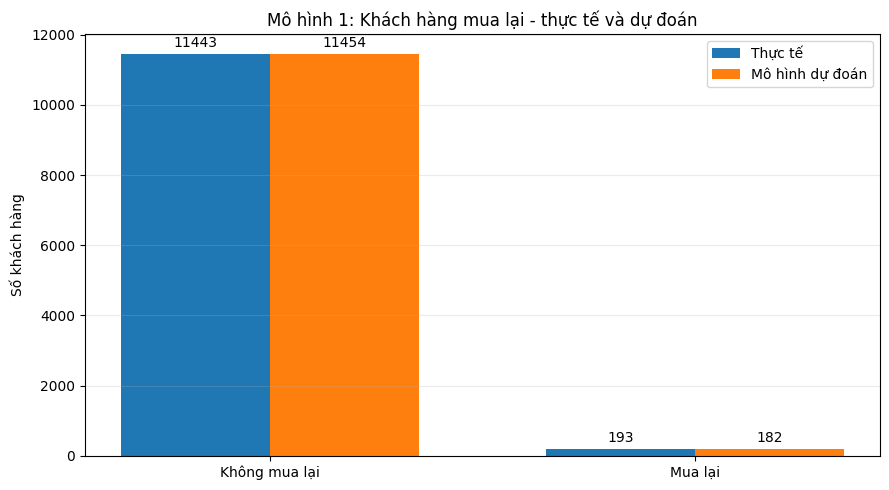

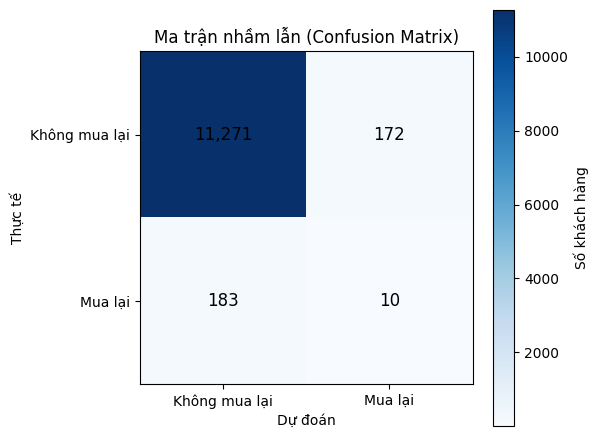

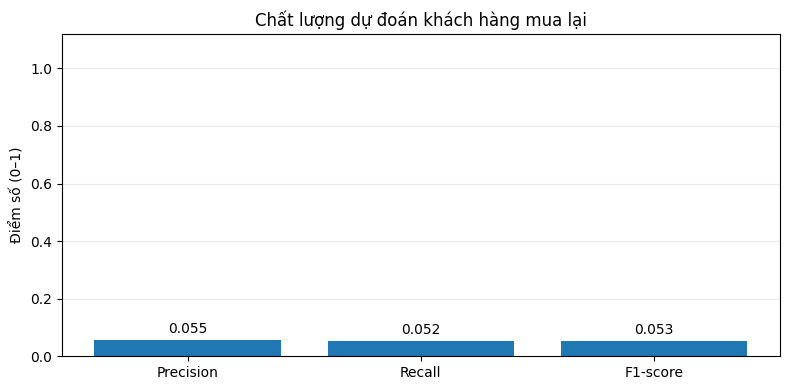

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score
)

if all(v in globals() for v in ['test', 'test_prob', 'best_threshold']) and len(test):
    y_true = test['repeat_label'].astype(int).to_numpy()
    y_pred = (np.asarray(test_prob) >= best_threshold).astype(int)

    # Biểu đồ 1: Thực tế so với dự đoán
    labels = ['Không mua lại', 'Mua lại']
    actual_counts = [(y_true == i).sum() for i in [0, 1]]
    predicted_counts = [(y_pred == i).sum() for i in [0, 1]]

    x = np.arange(2)
    width = 0.35
    fig, ax = plt.subplots(figsize=(9, 5))
    b1 = ax.bar(x - width/2, actual_counts, width, label='Thực tế')
    b2 = ax.bar(x + width/2, predicted_counts, width, label='Mô hình dự đoán')

    ax.bar_label(b1, padding=3)
    ax.bar_label(b2, padding=3)
    ax.set_xticks(x, labels)
    ax.set_ylabel('Số khách hàng')
    ax.set_title('Mô hình 1: Khách hàng mua lại - thực tế và dự đoán')
    ax.legend()
    ax.grid(axis='y', alpha=0.25)
    plt.tight_layout()
    plt.show()

    # Biểu đồ 2: Ma trận nhầm lẫn
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1], labels=labels)
    ax.set_yticks([0, 1], labels=labels)
    ax.set_xlabel('Dự đoán')
    ax.set_ylabel('Thực tế')
    ax.set_title('Ma trận nhầm lẫn (Confusion Matrix)')

    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}', ha='center',
                    va='center', color='black', fontsize=12)

    fig.colorbar(im, ax=ax, label='Số khách hàng')
    plt.tight_layout()
    plt.show()

    # Biểu đồ 3: Các chỉ số phân loại
    metric_values = {
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-score': f1_score(y_true, y_pred, zero_division=0)
    }

    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(metric_values.keys(), metric_values.values())
    ax.bar_label(bars, labels=[f'{v:.3f}' for v in metric_values.values()],
                 padding=3)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel('Điểm số (0–1)')
    ax.set_title('Chất lượng dự đoán khách hàng mua lại')
    ax.grid(axis='y', alpha=0.25)
    plt.tight_layout()
    plt.show()

else:
    print('Chạy ô mô hình 1 trước để tạo test, test_prob và best_threshold.')

# 6. Mô hình 2 — Dự báo doanh thu theo tháng
So sánh baseline tháng gần nhất, seasonal-naive, Ridge có regularization và ExtraTrees. Chọn giữa Ridge/ExtraTrees bằng validation theo thời gian nằm bên trong train, sau đó đánh giá một lần trên các tháng test cuối theo kiểu recursive. Sau đánh giá, mô hình được fit lại trên toàn bộ lịch sử để dự báo 3 tháng tiếp theo.

**Giới hạn quan trọng**: Olist chỉ có khoảng hai năm dữ liệu theo tháng; số điểm thời gian ít nên mọi dự báo dài hạn đều bất định. Không chọn mô hình chỉ vì một đường dự báo trông đẹp; hãy so sánh MAE/RMSE/WAPE với baseline.

,model,validation_MAE
0,Ridge,67723.625218
1,ExtraTrees,125948.835403


Đánh giá recursive trên 5 tháng cuối; thuật toán chọn bằng validation: Ridge
Ridge: MAE=397,135 BRL | RMSE=611,272 BRL | WAPE=47.24%
Baseline tháng gần nhất: MAE=315,667 BRL | RMSE=528,048 BRL | WAPE=37.55%
Seasonal-naive: MAE=519,273 BRL | RMSE=534,161 BRL | WAPE=61.77%


,model,MAE,RMSE,WAPE_%
1,Baseline tháng gần nhất,315666.772000,528048.254163,37.550895
0,Ridge,397135.478188,611271.700009,47.242200
2,Seasonal-naive,519272.802000,534161.319364,61.771337


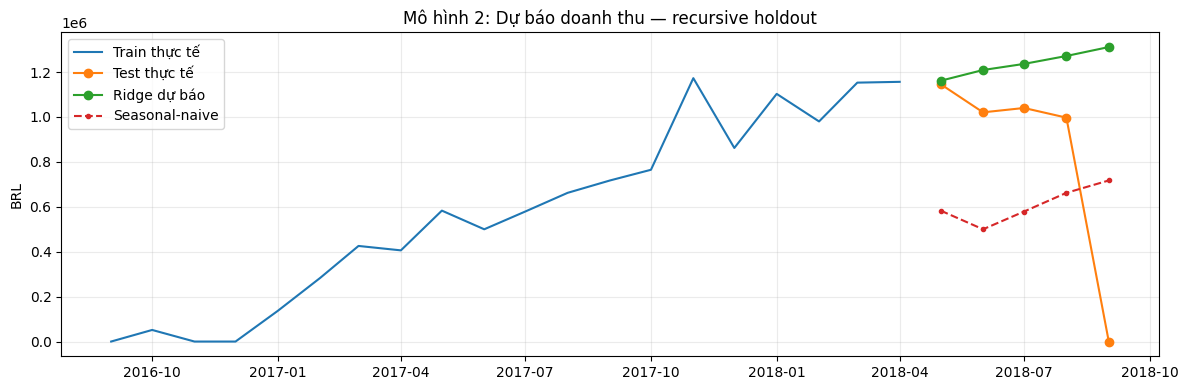

Đã fit lại mô hình dự báo tương lai bằng toàn bộ dữ liệu lịch sử.


In [55]:
# Mô hình 2 — So sánh baseline, Ridge và ExtraTrees; holdout nhiều bước không rò rỉ dữ liệu
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

monthly_ts = (
    monthly.set_index("month")["revenue"].sort_index()
    .asfreq("MS").astype(float).fillna(0.0)
)
monthly_ts.index = monthly_ts.index.to_period("M").to_timestamp()

feature_cols = [
    "lag_1", "lag_2", "lag_3", "rolling3",
    "month_sin", "month_cos", "trend_index"
]

def make_revenue_features(history, target_month):
    """Tạo đặc trưng chỉ từ lịch sử có trước tháng cần dự báo."""
    month = int(target_month.month)
    return {
        "lag_1": float(history.iloc[-1]),
        "lag_2": float(history.iloc[-2]),
        "lag_3": float(history.iloc[-3]),
        "rolling3": float(history.iloc[-3:].mean()),
        "month_sin": float(np.sin(2 * np.pi * month / 12)),
        "month_cos": float(np.cos(2 * np.pi * month / 12)),
        "trend_index": float(len(history))
    }

def make_supervised(series):
    rows = []
    for j in range(3, len(series)):
        row = make_revenue_features(series.iloc[:j], series.index[j])
        row["revenue"] = float(series.iloc[j])
        rows.append(row)
    return pd.DataFrame(rows).dropna()

def recursive_predict(model, history, target_index):
    history = history.copy()
    preds = []
    for month in target_index:
        row = make_revenue_features(history, month)
        x_next = pd.DataFrame([row]).reindex(columns=feature_cols)
        value = max(0.0, float(model.predict(x_next)[0]))
        preds.append(value)
        history.loc[month] = value
    return np.asarray(preds, dtype=float)

def report_forecast(name, y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    wape = np.abs(y_true - y_pred).sum() / max(np.abs(y_true).sum(), 1.0) * 100
    print(f"{name}: MAE={mae:,.0f} BRL | RMSE={rmse:,.0f} BRL | WAPE={wape:.2f}%")
    return {"model": name, "MAE": mae, "RMSE": rmse, "WAPE_%": wape}

if len(monthly_ts) >= 12:
    test_n = min(6, max(3, len(monthly_ts) // 5))
    train_series = monthly_ts.iloc[:-test_n].copy()
    test_series = monthly_ts.iloc[-test_n:].copy()

    # Chọn thuật toán bằng validation nằm bên trong train; không chọn theo test.
    val_n = min(3, max(2, len(train_series) // 5))
    fit_series = train_series.iloc[:-val_n].copy()
    val_series = train_series.iloc[-val_n:].copy()

    candidates = {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
        "ExtraTrees": ExtraTreesRegressor(
            n_estimators=200, min_samples_leaf=2, max_features=1.0,
            random_state=42, n_jobs=-1
        )
    }
    validation_rows = []
    fitted_candidates = {}
    for name, estimator in candidates.items():
        supervised = make_supervised(fit_series)
        if len(supervised) < 5:
            continue
        estimator = clone(estimator)
        estimator.fit(supervised[feature_cols], supervised["revenue"])
        val_pred = recursive_predict(estimator, fit_series, val_series.index)
        validation_rows.append({
            "model": name,
            "validation_MAE": mean_absolute_error(val_series.values, val_pred)
        })
        fitted_candidates[name] = estimator

    if validation_rows:
        validation_table = pd.DataFrame(validation_rows).sort_values("validation_MAE")
        display(validation_table)
        selected_name = str(validation_table.iloc[0]["model"])
    else:
        selected_name = "Ridge"
        print("Validation có quá ít mẫu; dùng Ridge regularized như phương pháp đơn giản.")

    # Huấn luyện lại trên toàn bộ phần train rồi dự báo đệ quy cho test.
    selected_template = candidates[selected_name]
    train_supervised = make_supervised(train_series)
    if len(train_supervised) < 3:
        selected_name = "Ridge"
        selected_template = candidates["Ridge"]
    revenue_model = clone(selected_template)
    revenue_model.fit(train_supervised[feature_cols], train_supervised["revenue"])
    recursive_preds = recursive_predict(revenue_model, train_series, test_series.index)

    last_value_preds = np.repeat(float(train_series.iloc[-1]), len(test_series))
    hist = train_series.copy()
    seasonal_preds = []
    for month in test_series.index:
        prior_year_month = month - pd.DateOffset(months=12)
        value = float(hist.loc[prior_year_month]) if prior_year_month in hist.index else float(hist.iloc[-1])
        seasonal_preds.append(value)
        hist.loc[month] = value

    print(f"Đánh giá recursive trên {test_n} tháng cuối; thuật toán chọn bằng validation: {selected_name}")
    results = [
        report_forecast(selected_name, test_series.values, recursive_preds),
        report_forecast("Baseline tháng gần nhất", test_series.values, last_value_preds),
        report_forecast("Seasonal-naive", test_series.values, seasonal_preds)
    ]
    forecast_comparison = pd.DataFrame(results).sort_values("WAPE_%")
    display(forecast_comparison)

    plt.figure(figsize=(12, 4))
    plt.plot(train_series.index, train_series.values, label="Train thực tế")
    plt.plot(test_series.index, test_series.values, marker="o", label="Test thực tế")
    plt.plot(test_series.index, recursive_preds, marker="o", label=f"{selected_name} dự báo")
    plt.plot(test_series.index, seasonal_preds, marker=".", linestyle="--", label="Seasonal-naive")
    plt.title("Mô hình 2: Dự báo doanh thu — recursive holdout")
    plt.ylabel("BRL"); plt.legend(); plt.grid(True, alpha=.25); plt.tight_layout(); plt.show()

    # Sau khi đánh giá xong, fit lại trên toàn bộ lịch sử để dùng dự báo tương lai.
    full_supervised = make_supervised(monthly_ts)
    revenue_model = clone(selected_template)
    revenue_model.fit(full_supervised[feature_cols], full_supervised["revenue"])
    print("Đã fit lại mô hình dự báo tương lai bằng toàn bộ dữ liệu lịch sử.")
else:
    revenue_model = None
    print(f"Chỉ có {len(monthly_ts)} tháng; cần ít nhất 12 tháng để đánh giá có ý nghĩa.")


,month,forecast_revenue_brl
0,2018-10-01,600005.741906
1,2018-11-01,521195.784219
2,2018-12-01,515901.048385


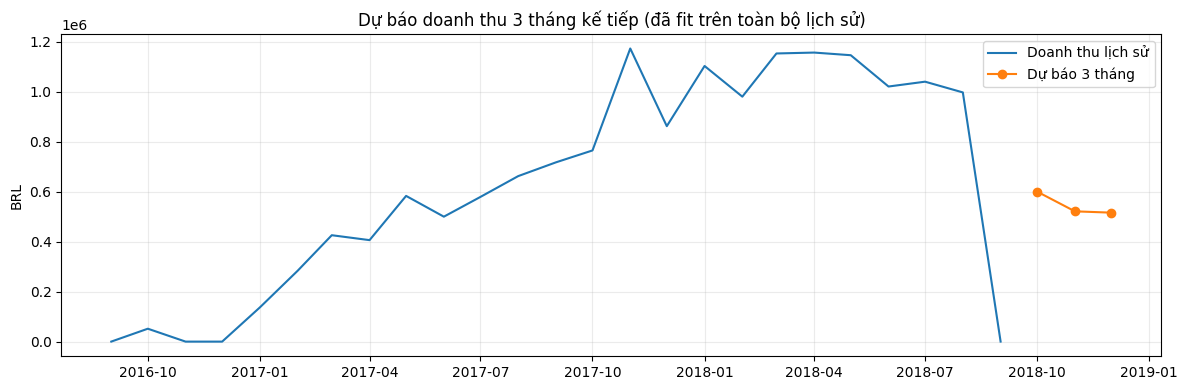

In [58]:
# Dự báo 3 tháng kế tiếp; ô mô hình 2 đã fit revenue_model trên toàn bộ lịch sử.
if revenue_model is not None and len(monthly_ts) >= 12:
    history = monthly_ts.copy()
    future_rows = []
    for _ in range(3):
        next_month = history.index.max() + pd.offsets.MonthBegin(1)
        row = make_revenue_features(history, next_month)
        x_next = pd.DataFrame([row]).reindex(columns=feature_cols)
        forecast = max(0.0, float(revenue_model.predict(x_next)[0]))
        future_rows.append({"month": next_month, "forecast_revenue_brl": forecast})
        history.loc[next_month] = forecast

    forecast_df = pd.DataFrame(future_rows)
    display(forecast_df)
    plt.figure(figsize=(12, 4))
    plt.plot(monthly_ts.index, monthly_ts.values, label="Doanh thu lịch sử")
    plt.plot(forecast_df["month"], forecast_df["forecast_revenue_brl"],
             marker="o", label="Dự báo 3 tháng")
    plt.title("Dự báo doanh thu 3 tháng kế tiếp (đã fit trên toàn bộ lịch sử)")
    plt.ylabel("BRL"); plt.legend(); plt.grid(True, alpha=.25); plt.tight_layout(); plt.show()
else:
    print("Chạy ô mô hình 2 trước và kiểm tra đủ dữ liệu.")


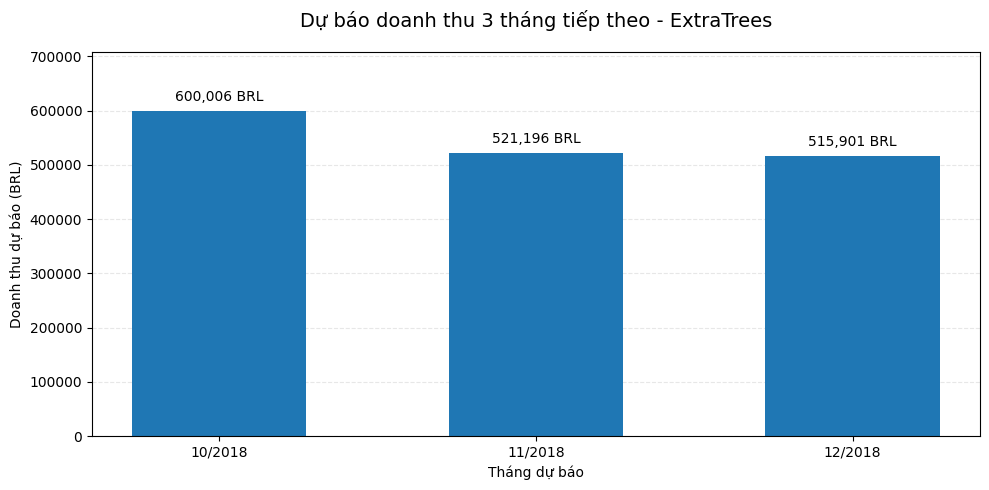

In [59]:
# Biểu đồ cột: Dự báo doanh thu 3 tháng tiếp theo
import matplotlib.pyplot as plt
import pandas as pd

if 'forecast_df' in globals() and not forecast_df.empty:
    chart_df = forecast_df.copy()
    chart_df['month'] = pd.to_datetime(chart_df['month'])
    chart_df = chart_df.sort_values('month')

    month_labels = chart_df['month'].dt.strftime('%m/%Y')
    revenues = chart_df['forecast_revenue_brl']

    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.bar(
        month_labels,
        revenues,
        width=0.55
    )

    # Hiển thị giá trị doanh thu trên đầu mỗi cột
    ax.bar_label(
        bars,
        labels=[f'{v:,.0f} BRL' for v in revenues],
        padding=5,
        fontsize=10
    )

    ax.set_title(
        'Dự báo doanh thu 3 tháng tiếp theo - ExtraTrees',
        fontsize=14,
        pad=18
    )
    ax.set_xlabel('Tháng dự báo')
    ax.set_ylabel('Doanh thu dự báo (BRL)')

    ax.set_ylim(0, max(revenues) * 1.18)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()

else:
    print(
        'Chưa có forecast_df. '
        'Hãy chạy cell dự báo 3 tháng của mô hình 2 trước.'
    )

# 7. Mô hình 3 — Phân khúc khách hàng RFM + K-Means
**- Recency:** số ngày từ lần mua gần nhất đến ngày mua gần nhất có trong dataset.

**- Frequency:** số đơn hợp lệ.

**- Monetary:** tổng giá trị thanh toán của các đơn hợp lệ (BRL).

Các biến được log-transform và chuẩn hóa bằng RobustScaler để giảm ảnh hưởng của độ lệch và ngoại lệ. So sánh nhiều giá trị k bằng Silhouette Score trên mẫu cố định để tiết kiệm thời gian, sau đó kiểm tra kích thước và hồ sơ từng cụm. K-Means là phân cụm, không phải mô hình dự đoán nhãn thực tế; mã cụm không có thứ tự tốt/xấu cố định.

In [60]:
rfm_sql = """
WITH pay AS (SELECT order_id,sum(payment_value)::float AS payment_value
             FROM olist_order_payments_dataset GROUP BY order_id),
base AS (
 SELECT c.customer_unique_id,o.order_id,o.order_purchase_timestamp,
        coalesce(pay.payment_value,0) AS payment_value
 FROM olist_customers_dataset c JOIN olist_orders_dataset o USING(customer_id)
 LEFT JOIN pay USING(order_id)
 WHERE o.order_status NOT IN ('canceled','unavailable')
   AND o.order_purchase_timestamp IS NOT NULL
)
SELECT customer_unique_id,
       max(order_purchase_timestamp) AS last_purchase,
       count(distinct order_id) AS frequency,
       sum(payment_value) AS monetary,
       max(order_purchase_timestamp) AS reference_date
FROM base GROUP BY customer_unique_id
"""
rfm = pd.read_sql_query(text(rfm_sql),engine,parse_dates=['last_purchase','reference_date'])
reference_date = rfm['last_purchase'].max()
rfm['recency'] = (reference_date-rfm['last_purchase']).dt.days
rfm = rfm[['customer_unique_id','recency','frequency','monetary']].replace([np.inf,-np.inf],np.nan).dropna()
rfm = rfm[(rfm['monetary']>=0) & (rfm['frequency']>=1)].copy()
print('Mốc tính Recency:',reference_date,'| khách hàng:',len(rfm))
display(rfm.describe().T)

Mốc tính Recency: 2018-09-03 09:06:57 | khách hàng: 94990


,count,mean,std,min,25%,50%,75%,max
recency,94990.0,242.448374,152.999947,0.0,118.0,223.0,351.00,728.00
frequency,94990.0,1.033867,0.210826,1.0,1.0,1.0,1.00,16.00
monetary,94990.0,165.692568,226.740288,0.0,63.1,107.9,182.94,13664.08


In [62]:
# Mô hình 3 — Phân cụm RFM: chuẩn hóa dữ liệu lệch, so sánh k và kiểm tra quy mô cụm
from sklearn.cluster import KMeans
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

rfm_model_data = rfm[["recency", "frequency", "monetary"]].copy()
for col in ["recency", "frequency", "monetary"]:
    rfm_model_data[col] = np.log1p(rfm_model_data[col].clip(lower=0))

scaler = RobustScaler()
rfm_scaled = scaler.fit_transform(rfm_model_data)
k_scores = pd.DataFrame()

if len(rfm) >= 20:
    candidate_ks = range(2, min(7, len(rfm) - 1) + 1)
    scores = []
    # Dùng cùng cỡ mẫu và random_state để so sánh silhouette công bằng, tiết kiệm thời gian.
    sil_sample = min(3000, len(rfm_scaled))
    for k_candidate in candidate_ks:
        candidate = KMeans(n_clusters=k_candidate, random_state=42, n_init=10)
        labels = candidate.fit_predict(rfm_scaled)
        score = silhouette_score(
            rfm_scaled, labels, sample_size=sil_sample, random_state=42
        )
        sizes = pd.Series(labels).value_counts(normalize=True)
        scores.append({
            "k": k_candidate,
            "silhouette": score,
            "smallest_cluster_pct": 100 * sizes.min()
        })
    k_scores = pd.DataFrame(scores).sort_values("silhouette", ascending=False).reset_index(drop=True)
    display(k_scores)
    k = int(k_scores.iloc[0]["k"])
    print(f"Chọn k={k} theo silhouette; cần kiểm tra thêm quy mô và ý nghĩa nghiệp vụ của cụm.")
else:
    if len(rfm) < 3:
        raise ValueError("Cần ít nhất 3 khách hàng để thực hiện K-Means.")
    k = min(3, len(rfm) - 1)
    print(f"Mẫu ít; dùng k={k} tạm thời và không xem đây là phân cụm đã tối ưu.")

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
rfm["cluster"] = kmeans.fit_predict(rfm_scaled)
cluster_profile = rfm.groupby("cluster").agg(
    customers=("customer_unique_id", "count"),
    median_recency_days=("recency", "median"),
    avg_orders=("frequency", "mean"),
    median_spend_brl=("monetary", "median"),
    avg_spend_brl=("monetary", "mean")
).round(2).sort_values("median_spend_brl", ascending=False)
cluster_profile["customer_share_pct"] = (
    cluster_profile["customers"] / cluster_profile["customers"].sum() * 100
).round(2)
display(cluster_profile)

if len(rfm) > k:
    sil_final = silhouette_score(
        rfm_scaled, rfm["cluster"],
        sample_size=min(3000, len(rfm_scaled)), random_state=42
    )
    print("Silhouette của phân cụm cuối:", round(sil_final, 4))
    if (cluster_profile["customer_share_pct"] < 2).any():
        print("Lưu ý: có cụm chiếm dưới 2% khách hàng; hãy kiểm tra cụm nhỏ trước khi diễn giải.")
print("Lưu ý: cluster 0/1/2 là mã kỹ thuật, không phải nhãn thực tế có đúng/sai.")


,k,silhouette,smallest_cluster_pct
0,2,0.413370,25.194231
1,3,0.381625,19.169386
2,6,0.340203,9.486262
3,5,0.339958,11.229603
4,4,0.336403,13.386672
5,7,0.332138,6.029056


Chọn k=2 theo silhouette; cần kiểm tra thêm quy mô và ý nghĩa nghiệp vụ của cụm.


,customers,median_recency_days,avg_orders,median_spend_brl,avg_spend_brl,customer_share_pct
cluster,,,,,,
1,23932,61.0,1.04,115.00,178.59,25.19
0,71058,281.0,1.03,105.98,161.35,74.81


Silhouette của phân cụm cuối: 0.4134
Lưu ý: cluster 0/1/2 là mã kỹ thuật, không phải nhãn thực tế có đúng/sai.


In [63]:
import plotly.express as px

# Vẽ một mẫu duy nhất để điểm, màu cụm và hover_data cùng hàng.
if len(rfm):
    rfm_plot = rfm.sample(min(5000, len(rfm)), random_state=42).copy()
    rfm_plot['cluster_label'] = rfm_plot['cluster'].astype(str)
    fig = px.scatter(
        rfm_plot, x='recency', y='monetary', color='cluster_label',
        size='frequency', hover_data=['customer_unique_id'],
        title='Phân khúc RFM: Recency vs Monetary',
        labels={'cluster_label': 'Cụm', 'recency': 'Recency (ngày)',
                'monetary': 'Monetary (BRL)'}
    )
    fig.show()
else:
    print('Không có dữ liệu RFM để vẽ.')


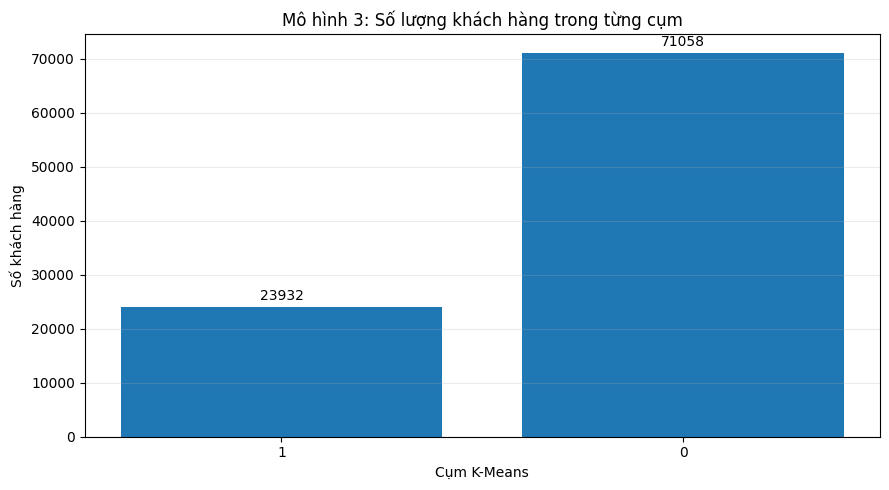

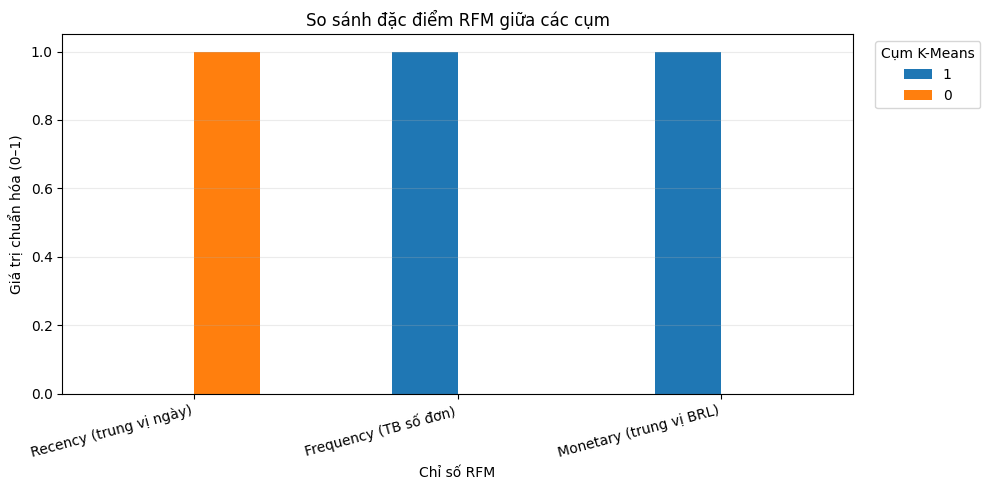

Bảng đặc điểm RFM theo đơn vị gốc:


,customer_count,recency_median,frequency_mean,monetary_median
cluster,,,,
1,23932,61.0,1.04,115.00
0,71058,281.0,1.03,105.98


In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required_cols = {
    'recency', 'frequency', 'monetary', 'cluster'
}

if required_cols.issubset(rfm.columns) and len(rfm):
    # Tổng hợp đặc điểm từng cụm
    profile = rfm.groupby('cluster').agg(
        customer_count=('cluster', 'size'),
        recency_median=('recency', 'median'),
        frequency_mean=('frequency', 'mean'),
        monetary_median=('monetary', 'median')
    ).sort_values('monetary_median', ascending=False)

    # Biểu đồ 1: Số lượng khách hàng mỗi cụm
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(
        profile.index.astype(str),
        profile['customer_count']
    )
    ax.bar_label(bars, padding=3, fmt='%.0f')
    ax.set_title('Mô hình 3: Số lượng khách hàng trong từng cụm')
    ax.set_xlabel('Cụm K-Means')
    ax.set_ylabel('Số khách hàng')
    ax.grid(axis='y', alpha=0.25)
    plt.tight_layout()
    plt.show()

    # Biểu đồ 2: So sánh đặc điểm RFM giữa các cụm
    # Chuẩn hóa từng chỉ số theo min-max để so sánh trên cùng thang 0–1.
    metric_cols = [
        'recency_median',
        'frequency_mean',
        'monetary_median'
    ]

    display_names = {
        'recency_median': 'Recency (trung vị ngày)',
        'frequency_mean': 'Frequency (TB số đơn)',
        'monetary_median': 'Monetary (trung vị BRL)'
    }

    normalized = profile[metric_cols].copy()
    for col in metric_cols:
        low, high = normalized[col].min(), normalized[col].max()
        if high > low:
            normalized[col] = (normalized[col] - low) / (high - low)
        else:
            normalized[col] = 0.5

    normalized = normalized.rename(columns=display_names)

    fig, ax = plt.subplots(figsize=(10, 5))
    normalized.T.plot(kind='bar', ax=ax)
    ax.set_title('So sánh đặc điểm RFM giữa các cụm')
    ax.set_xlabel('Chỉ số RFM')
    ax.set_ylabel('Giá trị chuẩn hóa (0–1)')
    ax.legend(title='Cụm K-Means', bbox_to_anchor=(1.02, 1),
              loc='upper left')
    ax.grid(axis='y', alpha=0.25)
    plt.xticks(rotation=15, ha='right')
    plt.tight_layout()
    plt.show()

    # Bảng số liệu gốc để diễn giải chính xác từng cụm
    print('Bảng đặc điểm RFM theo đơn vị gốc:')
    display(profile.round(2))

else:
    print(
        'Chạy các ô tạo RFM và K-Means trước. '
        'Cần có recency, frequency, monetary và cluster.'
    )

## 8. Lưu kết quả ra CSV
File sẽ được tạo trong phiên Colab hiện tại; tải xuống qua Files bên trái hoặc dùng `files.download`. Không ghi dữ liệu cá nhân nhạy cảm ra ngoài khi không cần thiết. Customer IDs trong Olist là mã định danh dataset.

In [65]:
from pathlib import Path
out_dir = Path('/content/olist_outputs'); out_dir.mkdir(exist_ok=True)
monthly.to_csv(out_dir/'monthly_revenue_source.csv',index=False)
if 'forecast_df' in globals(): forecast_df.to_csv(out_dir/'revenue_forecast_3_months.csv',index=False)
rfm.to_csv(out_dir/'customer_rfm_clusters.csv',index=False)
if 'preview' in globals(): preview.to_csv(out_dir/'repeat_purchase_predictions_sample.csv',index=False)
print('Đã lưu:',*[str(p) for p in out_dir.iterdir()],sep='\n')

Đã lưu:
/content/olist_outputs/repeat_purchase_predictions_sample.csv
/content/olist_outputs/revenue_forecast_3_months.csv
/content/olist_outputs/monthly_revenue_source.csv
/content/olist_outputs/customer_rfm_clusters.csv
